11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 55s 32ms/step - accuracy: 0.9294 - loss: 0.2244 - val_accuracy: 0.9860 - val_loss: 0.0484
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 54s 32ms/step - accuracy: 0.9760 - loss: 0.0817 - val_accuracy: 0.9902 - val_loss: 0.0374
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 80s 31ms/step - accuracy: 0.9817 - loss: 0.0602 - val_accuracy: 0.9905 - val_loss: 0.0334
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 52s 31ms/step - accuracy: 0.9854 - loss: 0.0474 - val_accuracy: 0.9922 - val_loss: 0.0286
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 82s 31ms/step - accuracy: 0.9876 - loss: 0.0396 - val_accuracy: 0.9920 - val_loss: 0.0298
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 53s 31ms/step - accuracy: 0.9896 - loss: 0.0345 - val_accuracy: 0.9908 - val_loss: 0.0342
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 53s 31ms/step - accuracy: 0.9905 - loss: 0.0297 - val_accuracy: 0.9912 - val_loss: 0.0342
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 52s 31ms/step - accuracy: 0.9914 -

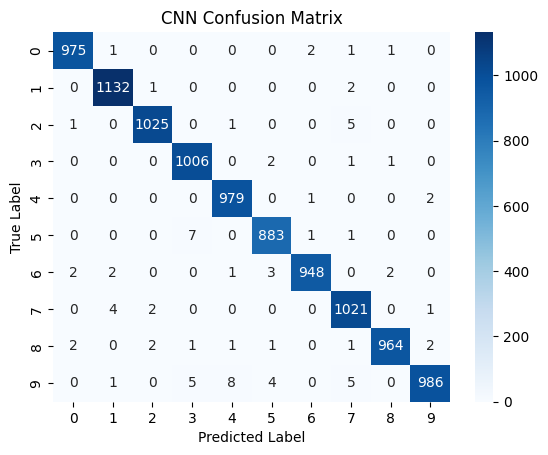

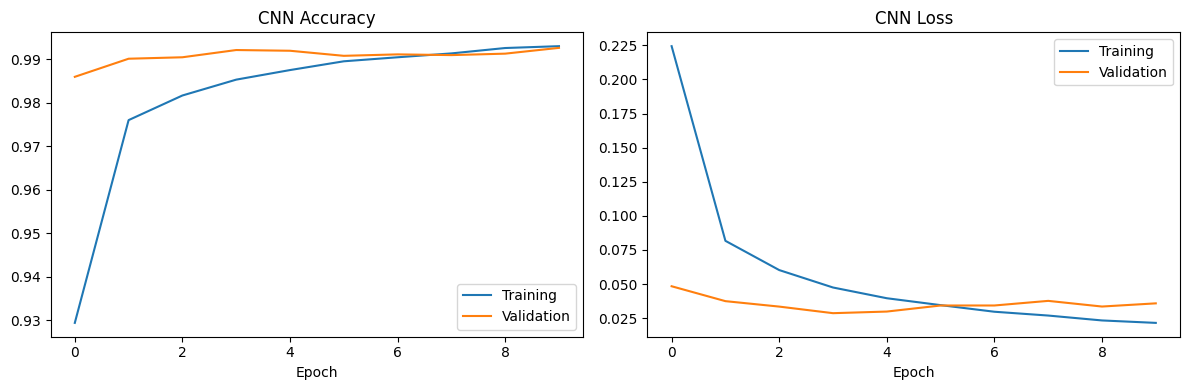

In [6]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

(x_train_cnn, y_train_cnn), (x_test_cnn, y_test_cnn) = keras.datasets.mnist.load_data()

x_train_cnn = x_train_cnn.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test_cnn = x_test_cnn.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print("Training shape:", x_train_cnn.shape)
print("Testing shape:", x_test_cnn.shape)

model_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation='relu'),
            layers.MaxPooling2D((2, 2)),
                layers.Conv2D(64, (3, 3), activation='relu'),
                    layers.MaxPooling2D((2, 2)),
                        layers.Flatten(),
                            layers.Dense(128, activation='relu'),
                                layers.Dropout(0.5),
                                    layers.Dense(10, activation='softmax')
                                    ])

model_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cnn.summary()
history_cnn = model_cnn.fit(x_train_cnn, y_train_cnn, epochs=10, validation_split=0.1)
loss_cnn, accuracy_cnn = model_cnn.evaluate(x_test_cnn, y_test_cnn, verbose=0)
print("Test Loss:", round(loss_cnn, 4))
print("Test Accuracy:", round(accuracy_cnn, 4))
y_pred_cnn = np.argmax(model_cnn.predict(x_test_cnn, verbose=0), axis=1)
print(classification_report(y_test_cnn, y_pred_cnn))
cm_cnn = confusion_matrix(y_test_cnn, y_pred_cnn)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues')
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Training')
plt.plot(history_cnn.history['val_accuracy'], label='Validation')
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Training')
plt.plot(history_cnn.history['val_loss'], label='Validation')
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()
